# LAB 2 – Bài 5: Phân lớp bệnh tim – Heart Disease (Trang 26–27)
Thuộc tính quyết định: `target` (0 = không bệnh, 1 = có bệnh tim). Cần file `heart.csv`.


In [1]:
HO_TEN = "Lê Quốc Trung"
MSSV = "6451071082"


def in_ten():
    print(f"{HO_TEN} - {MSSV}")


in_ten()

Lê Quốc Trung - 6451071082


## Chuẩn bị: thư viện và hàm dùng chung

In [2]:
%matplotlib inline
import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn import tree
from sklearn.naive_bayes import GaussianNB
from sklearn import metrics


import urllib.request

# ID file trên Google Drive (lấy từ link chia sẻ .../file/d/<ID>/view)
FILE_IDS = {
    "adult.data.csv": "1BYKP73pyzphA5YHR1fVvn2A0kBpr09TB",
    "adult.test.csv": "1Vh7e1IBL0SRxjT3gU_v_rnIcAT18griD",
    "heart.csv": "10N9jGzMn-MagDWXORdP-qIpwC3omZJHb",
    "mushrooms.csv": "11OXFpnwUwK_Ka9BFmboMoT9RhTRe3CFW",
    "winequality-red.csv": "1rzLiUi64RLmMV8ApudCt6aJyv_OkhADH",
}


def tai_tu_drive(file_id, ten_luu):
    """Tải file công khai từ Google Drive theo ID và lưu thành ten_luu."""
    url = f"https://drive.google.com/uc?export=download&id={file_id}"
    req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
    with urllib.request.urlopen(req, timeout=120) as r:
        noi_dung = r.read()
    if noi_dung.lstrip()[:15].lower().startswith((b"<!doctype html", b"<html")):
        raise RuntimeError("Drive trả về trang web thay vì file: kiểm tra file đã chia sẻ 'Bất kỳ ai có đường liên kết' chưa.")
    with open(ten_luu, "wb") as f:
        f.write(noi_dung)


def tim_file(ten_file):
    """Trả về đường dẫn file dữ liệu: dùng bản có sẵn trong máy, nếu chưa có thì tải từ Drive theo FILE_IDS."""
    for thu_muc in [".", "data", "/content"]:
        p = os.path.join(thu_muc, ten_file)
        if os.path.isfile(p):
            print("Đã tìm thấy:", p)
            return p
    if ten_file not in FILE_IDS:
        raise FileNotFoundError(f"Không có file '{ten_file}' và cũng không có ID Drive tương ứng.")
    print(f"Đang tải '{ten_file}' từ Google Drive...")
    tai_tu_drive(FILE_IDS[ten_file], ten_file)
    print("Đã tải xong:", ten_file)
    return ten_file


ket_qua = {}   # lưu chỉ số của từng mô hình để so sánh ở Câu 10


def tinh_chi_so(y_true, y_pred, pos_label=None):
    d = {"Accuracy": metrics.accuracy_score(y_true, y_pred)}
    for avg in ("macro", "weighted"):
        p, r, f, _ = metrics.precision_recall_fscore_support(y_true, y_pred, average=avg, zero_division=0)
        d[f"Precision ({avg})"], d[f"Recall ({avg})"], d[f"F1 ({avg})"] = p, r, f
    if pos_label is not None:
        p, r, f, _ = metrics.precision_recall_fscore_support(
            y_true, y_pred, labels=[pos_label], average=None, zero_division=0)
        d[f"Precision [{pos_label}]"], d[f"Recall [{pos_label}]"], d[f"F1 [{pos_label}]"] = p[0], r[0], f[0]
    return d


def danh_gia_mo_hinh(ten, y_test, y_pred, labels, pos_label=None, cmap="Blues"):
    """In accuracy + classification report, vẽ heatmap ma trận nhầm lẫn, lưu chỉ số để so sánh."""
    score = metrics.accuracy_score(y_test, y_pred)
    print("Accuracy:", score)
    print("Report:\n", metrics.classification_report(y_test, y_pred, labels=labels, zero_division=0))
    cm = metrics.confusion_matrix(y_test, y_pred, labels=labels)
    plt.figure(figsize=(8, 8))
    sns.heatmap(cm, annot=True, fmt="d", linewidths=.5, square=True, cmap=cmap,
                xticklabels=labels, yticklabels=labels)
    plt.ylabel("Actual label")
    plt.xlabel("Predicted label")
    plt.title(f"{ten} Accuracy Score: {score:.4f}", size=15)
    plt.show()
    ket_qua[ten] = tinh_chi_so(y_test, y_pred, pos_label)
    return cm


def ve_cay(clf, feature_names, ten_file, max_depth=None, figsize=(50, 24), fontsize=10):
    """Vẽ cây quyết định và lưu thành file PNG (dpi=100)."""
    fig, ax = plt.subplots(figsize=figsize)
    tree.plot_tree(clf, max_depth=max_depth, feature_names=list(feature_names),
                   class_names=[str(c) for c in clf.classes_], filled=True, fontsize=fontsize, ax=ax)
    plt.savefig(ten_file, dpi=100)
    plt.show()
    print("Đã lưu cây vào file:", ten_file)

## Câu a): Nhập dữ liệu, xóa các dòng dữ liệu trống và đổi tên cột

In [3]:
in_ten()
data = pd.read_csv(tim_file("heart.csv"), encoding="utf-8-sig")   # utf-8-sig: bỏ ký tự BOM ở đầu file
print("Kích thước ban đầu:", data.shape)
print("Số ô trống mỗi cột:")
print(data.isna().sum())

data = data.dropna().reset_index(drop=True)          # xóa các dòng dữ liệu trống
data.columns = ['age', 'sex', 'chest_pain_type', 'resting_blood_pressure', 'cholesterol', 'fasting_blood_sugar', 'rest_ecg', 'max_heart_rate_achieved', 'exercise_induced_angina', 'st_depression', 'st_slope', 'num_major_vessels', 'thalassemia', 'target']
print("Kích thước sau khi xóa dòng trống:", data.shape)
data.info()
display(data.head())

Lê Quốc Trung - 6451071082
Đang tải 'heart.csv' từ Google Drive...
Đã tải xong: heart.csv
Kích thước ban đầu: (303, 14)
Số ô trống mỗi cột:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64
Kích thước sau khi xóa dòng trống: (303, 14)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   age                      303 non-null    int64  
 1   sex                      303 non-null    int64  
 2   chest_pain_type          303 non-null    int64  
 3   resting_blood_pressure   303 non-null    int64  
 4   cholesterol              303 non-null    int64  
 5   fasting_blood_sugar      303 non-null    int64  
 6   rest_ecg                 303 non-null    int64  
 7   max_heart_

,age,sex,chest_pain_type,resting_blood_pressure,cholesterol,fasting_blood_sugar,rest_ecg,max_heart_rate_achieved,exercise_induced_angina,st_depression,st_slope,num_major_vessels,thalassemia,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


## Câu 3: Khảo sát độ tương đồng giữa các cột bằng công thức Pearson
Vẽ heatmap (màu càng đậm → mức độ tương đồng càng thấp). Sau đó tự động tìm các cặp cột **feature** có |r| vượt ngưỡng và loại bỏ.

Lê Quốc Trung - 6451071082


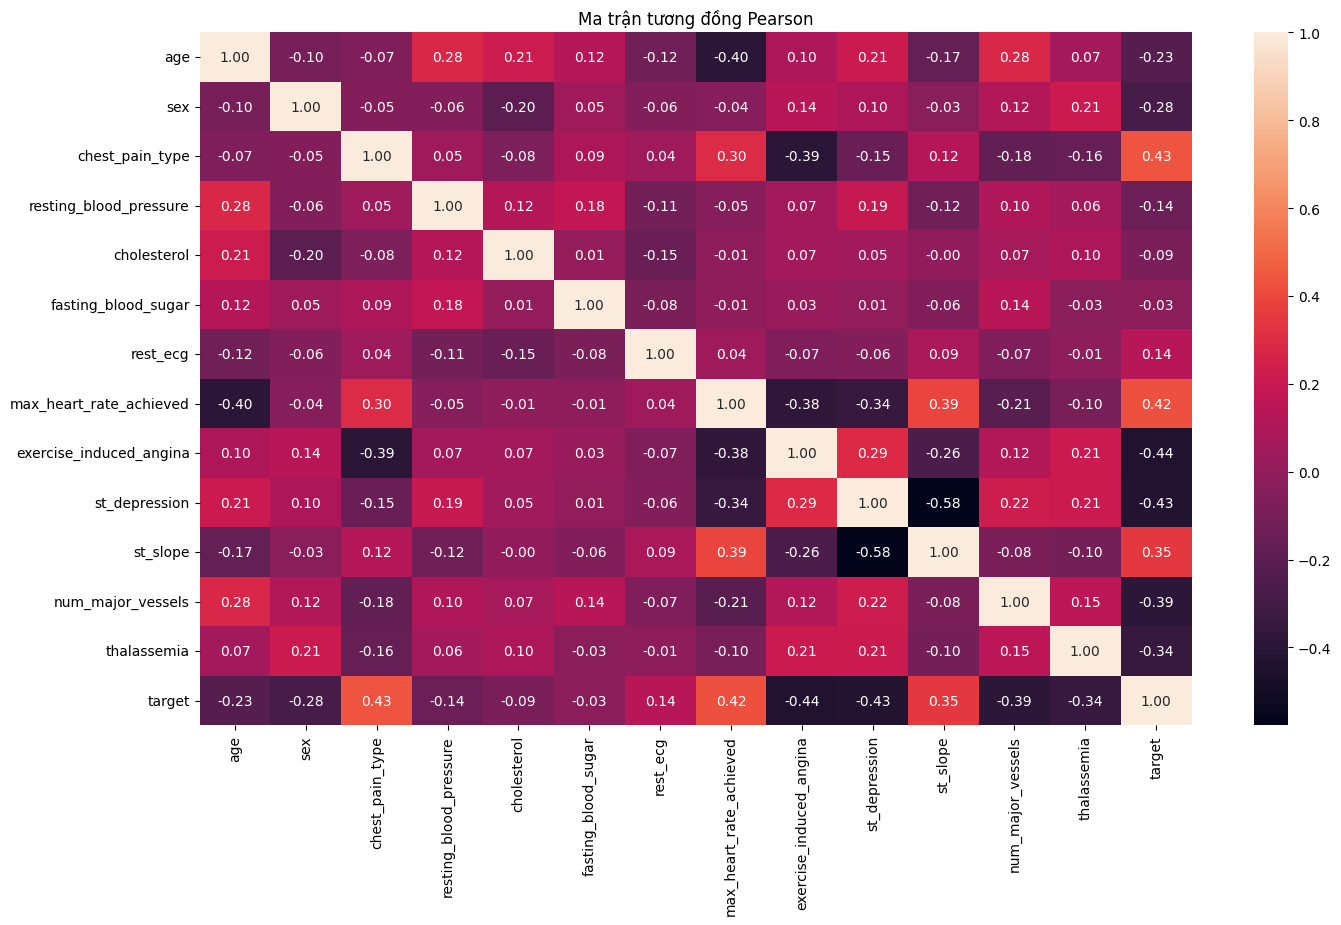

In [4]:
in_ten()
NHAN = "target"   # thuộc tính quyết định

plt.figure(figsize=(16, 9))
sns.heatmap(data.corr(method="pearson", numeric_only=True), annot=True, fmt=".2f")
plt.title("Ma trận tương đồng Pearson")
plt.show()

In [5]:
in_ten()
NGUONG_PEARSON = 0.8   # |r| > ngưỡng này được xem là tương đồng cao

corr = data.drop(columns=[NHAN]).corr(method="pearson", numeric_only=True).abs()
tam_giac_tren = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
cap_cao = [(a, b, round(float(tam_giac_tren.loc[a, b]), 3))
           for a in tam_giac_tren.index for b in tam_giac_tren.columns
           if pd.notna(tam_giac_tren.loc[a, b]) and tam_giac_tren.loc[a, b] > NGUONG_PEARSON]
cot_loai = sorted({b for _, b, _ in cap_cao})

if cap_cao:
    print("Các cặp cột tương đồng cao:", cap_cao)
    print("Loại bỏ các cột:", cot_loai)
else:
    print(f"Không có cặp cột nào có |r| > {NGUONG_PEARSON} => không cần loại bỏ cột nào.")

data = data.drop(columns=cot_loai)
print("Các cột còn lại:", list(data.columns))

Lê Quốc Trung - 6451071082
Không có cặp cột nào có |r| > 0.8 => không cần loại bỏ cột nào.
Các cột còn lại: ['age', 'sex', 'chest_pain_type', 'resting_blood_pressure', 'cholesterol', 'fasting_blood_sugar', 'rest_ecg', 'max_heart_rate_achieved', 'exercise_induced_angina', 'st_depression', 'st_slope', 'num_major_vessels', 'thalassemia', 'target']


## Câu 4: Tách các cột thành hai phần
`features` chứa các thuộc tính bình thường, `labels` chứa riêng thuộc tính quyết định.

In [6]:
in_ten()
features = data.drop(NHAN, axis=1)
labels = data[NHAN]
print("features:", features.shape, "| labels:", labels.shape)
print(labels.value_counts())

Lê Quốc Trung - 6451071082
features: (303, 13) | labels: (303,)
target
1    165
0    138
Name: count, dtype: int64


## Câu 5: Chuyển các cột không phải dạng số về one-hot vector
Xác định các cột không phải dạng số rồi dùng `pd.get_dummies`.

In [7]:
in_ten()
cot_chu = features.select_dtypes(exclude="number").columns
print("Các cột không phải dạng số:", list(cot_chu))

if len(cot_chu) > 0:
    features_onehot = pd.get_dummies(features, columns=cot_chu, dtype=int)
else:
    features_onehot = features.copy()
    print("=> Tất cả các cột đều là dạng số, không cần chuyển one-hot.")

print("Kích thước sau khi xử lý:", features_onehot.shape)
display(features_onehot.head())

Lê Quốc Trung - 6451071082
Các cột không phải dạng số: []
=> Tất cả các cột đều là dạng số, không cần chuyển one-hot.
Kích thước sau khi xử lý: (303, 13)


,age,sex,chest_pain_type,resting_blood_pressure,cholesterol,fasting_blood_sugar,rest_ecg,max_heart_rate_achieved,exercise_induced_angina,st_depression,st_slope,num_major_vessels,thalassemia
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2


## Câu 6: Chia dữ liệu thành hai phần huấn luyện (70%) và kiểm thử (30%)
Theo đề: `train_test_split(X, y, test_size=0.3, random_state=42)`.

In [8]:
in_ten()
X_train, X_test, y_train, y_test = train_test_split(features_onehot, labels, test_size=0.3, random_state=42)

LOP = sorted(labels.unique())
print("X_train:", X_train.shape, "| X_test:", X_test.shape)
print("Các lớp:", LOP)

Lê Quốc Trung - 6451071082
X_train: (212, 13) | X_test: (91, 13)
Các lớp: [np.int64(0), np.int64(1)]


## Câu 7: Xây dựng cây ID3 (`criterion="entropy"` – phân nhánh theo information gain)
Gồm 3 phần: huấn luyện + dự đoán → kiểm thử bằng ma trận nhầm lẫn → biểu diễn cây.

In [9]:
in_ten()
clf_id3 = tree.DecisionTreeClassifier(criterion="entropy", random_state=0)
clf_id3.fit(X_train, y_train)          # huấn luyện
id3_pred = clf_id3.predict(X_test)     # dự đoán trên dữ liệu kiểm thử
print("Số nút:", clf_id3.tree_.node_count, "| số lá:", clf_id3.get_n_leaves(), "| độ sâu:", clf_id3.get_depth())

Lê Quốc Trung - 6451071082
Số nút: 67 | số lá: 34 | độ sâu: 7


Lê Quốc Trung - 6451071082
Accuracy: 0.7252747252747253
Report:
               precision    recall  f1-score   support

           0       0.67      0.76      0.71        41
           1       0.78      0.70      0.74        50

    accuracy                           0.73        91
   macro avg       0.73      0.73      0.72        91
weighted avg       0.73      0.73      0.73        91



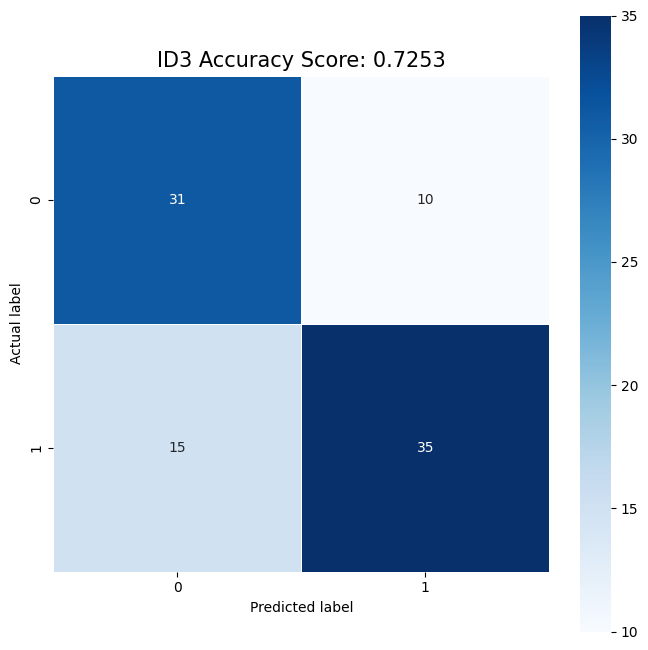

Ma trận nhầm lẫn (hàng = thực tế, cột = dự đoán):
[[31 10]
 [15 35]]


In [10]:
in_ten()
id3_cm = danh_gia_mo_hinh("ID3", y_test, id3_pred, LOP, pos_label=1, cmap="Blues")
print("Ma trận nhầm lẫn (hàng = thực tế, cột = dự đoán):")
print(id3_cm)

Lê Quốc Trung - 6451071082


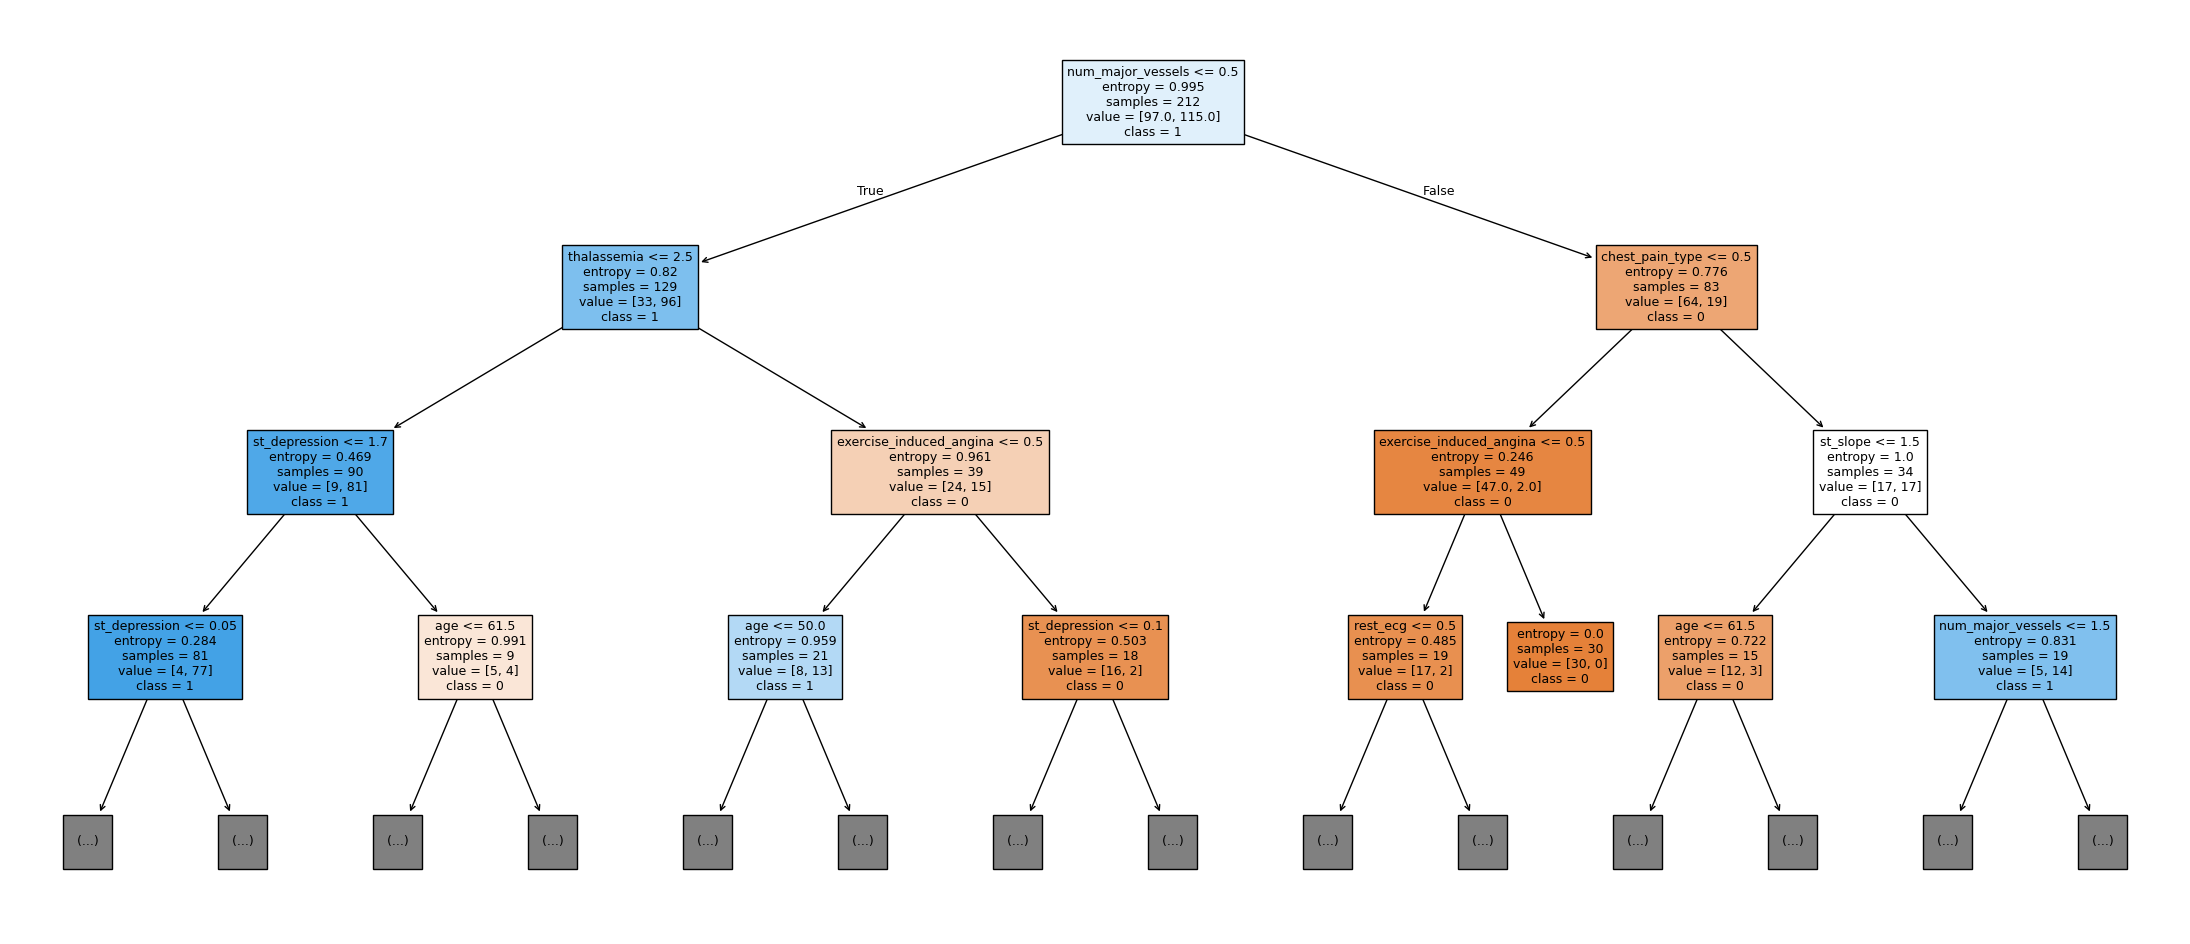

Đã lưu cây vào file: cay_ID3_rut_gon.png


In [11]:
in_ten()
# Cây rút gọn (3 mức trên cùng) để đọc được trên màn hình
ve_cay(clf_id3, X_train.columns, "cay_ID3_rut_gon.png", max_depth=3, figsize=(28, 12), fontsize=9)

Lê Quốc Trung - 6451071082


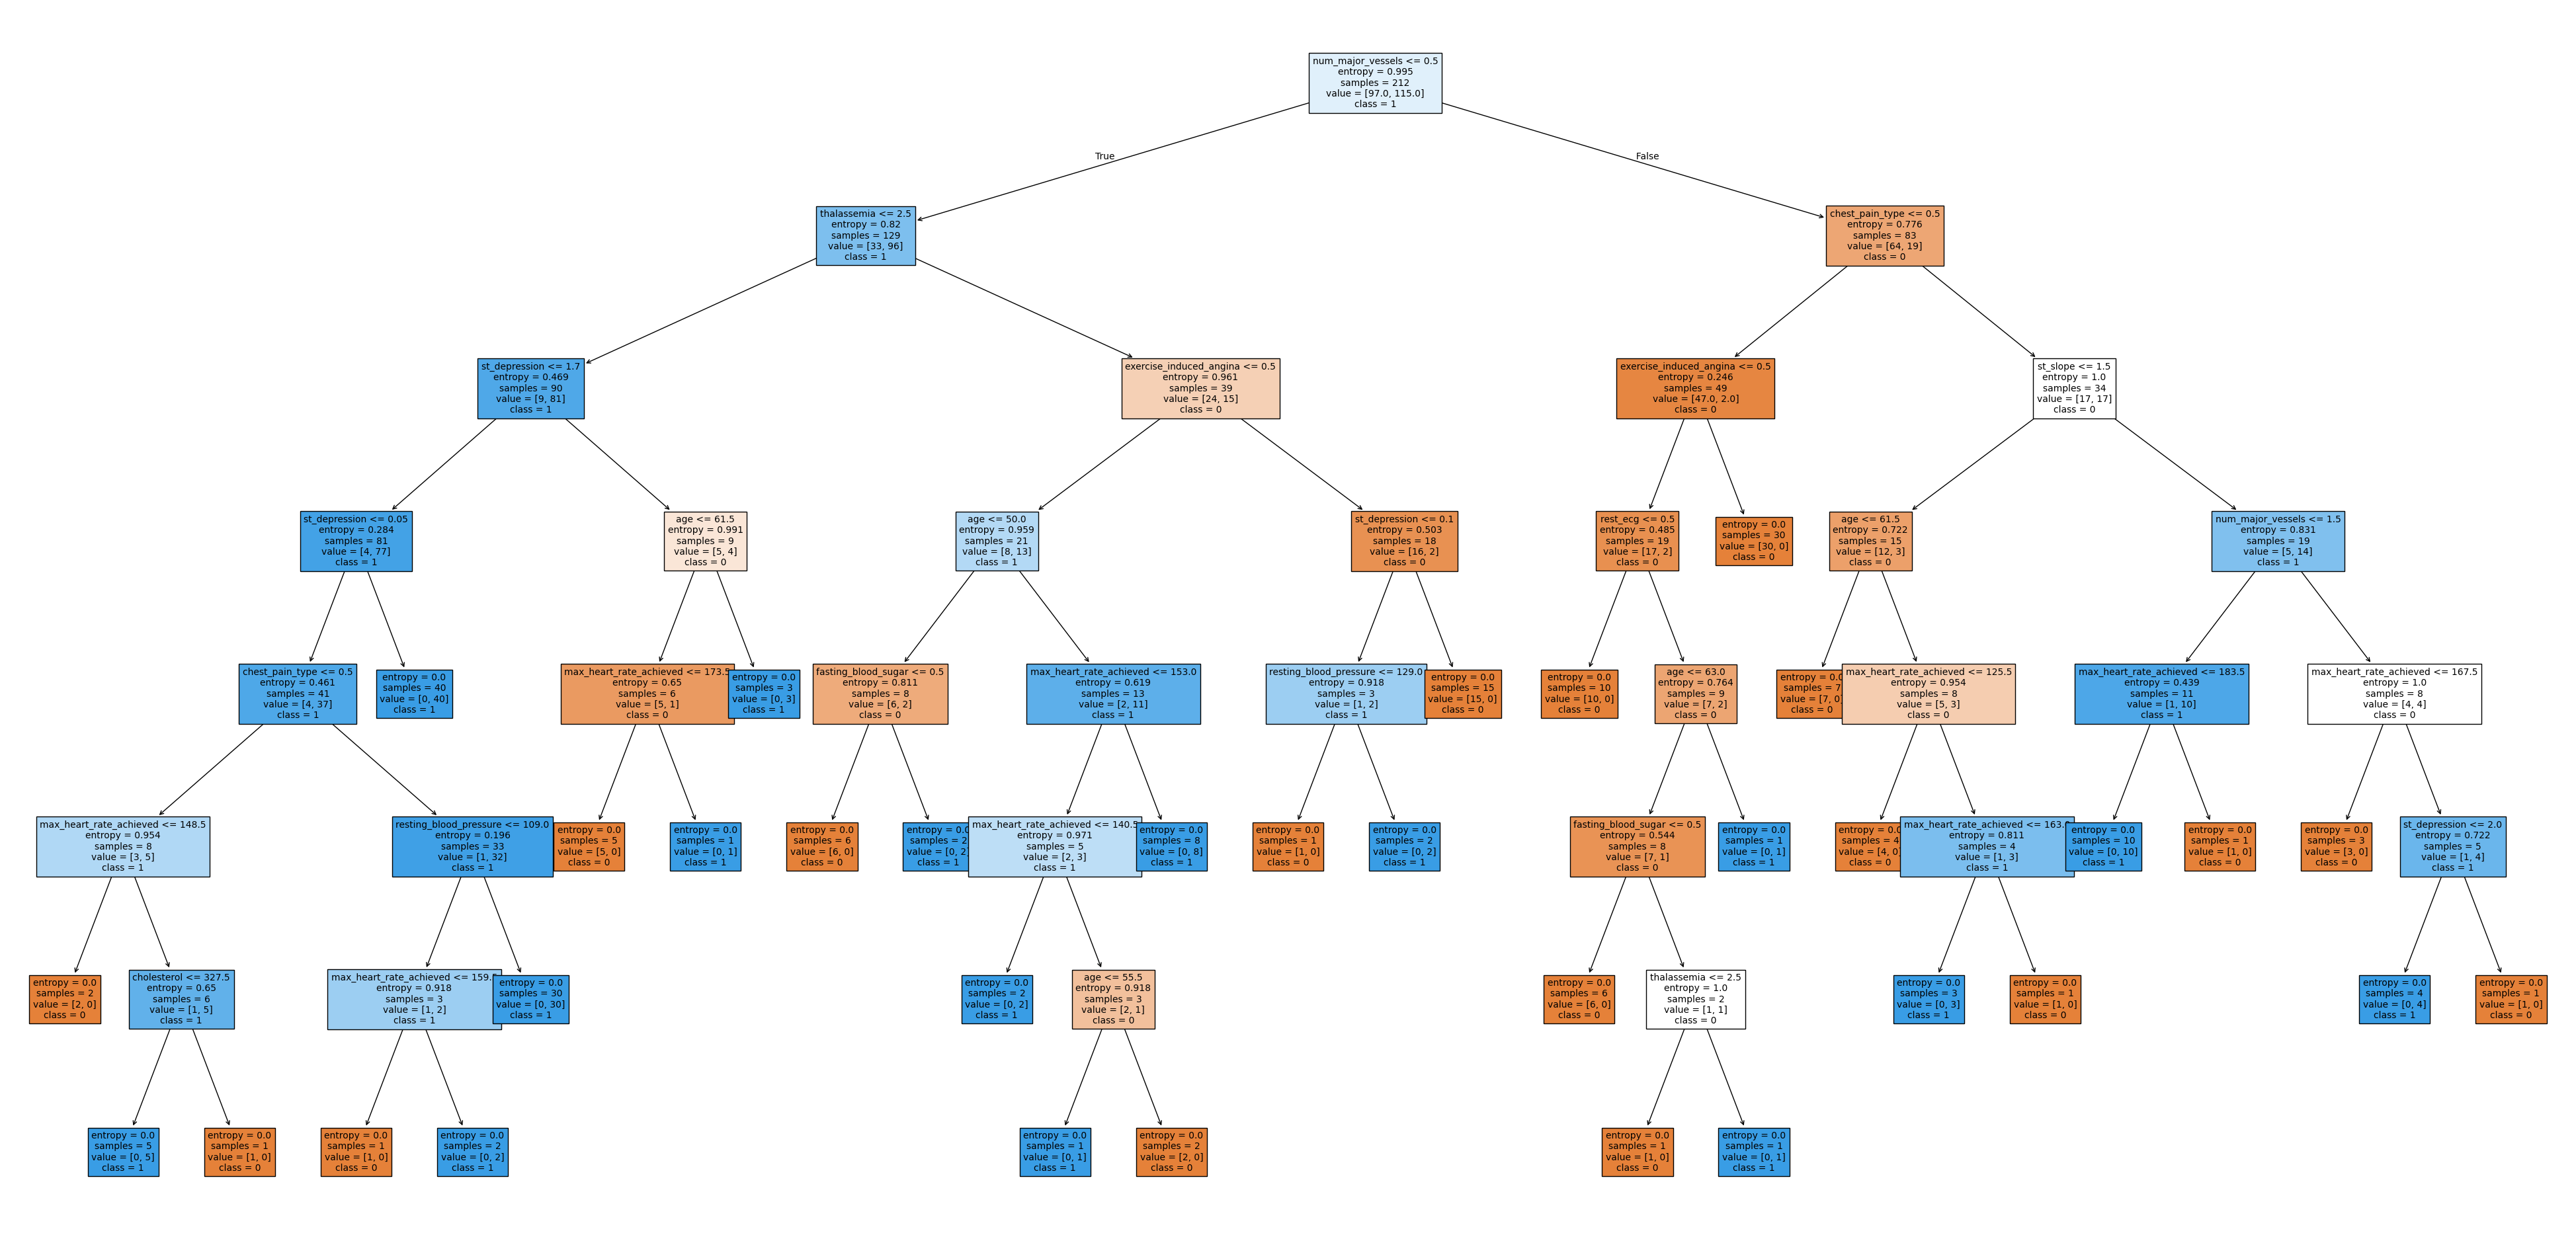

Đã lưu cây vào file: cay_ID3.png


In [12]:
in_ten()
VE_CAY_DAY_DU = True
if VE_CAY_DAY_DU:
    ve_cay(clf_id3, X_train.columns, "cay_ID3.png", figsize=(50, 24), fontsize=10)

## Câu 8: Xây dựng cây CART (`criterion="gini"`)
Thực hiện tương tự Câu 7, thay `criterion="gini"`.

In [13]:
in_ten()
clf_cart = tree.DecisionTreeClassifier(criterion="gini", random_state=0)
clf_cart.fit(X_train, y_train)
cart_pred = clf_cart.predict(X_test)
print("Số nút:", clf_cart.tree_.node_count, "| số lá:", clf_cart.get_n_leaves(), "| độ sâu:", clf_cart.get_depth())

Lê Quốc Trung - 6451071082
Số nút: 75 | số lá: 38 | độ sâu: 9


Lê Quốc Trung - 6451071082
Accuracy: 0.7252747252747253
Report:
               precision    recall  f1-score   support

           0       0.67      0.76      0.71        41
           1       0.78      0.70      0.74        50

    accuracy                           0.73        91
   macro avg       0.73      0.73      0.72        91
weighted avg       0.73      0.73      0.73        91



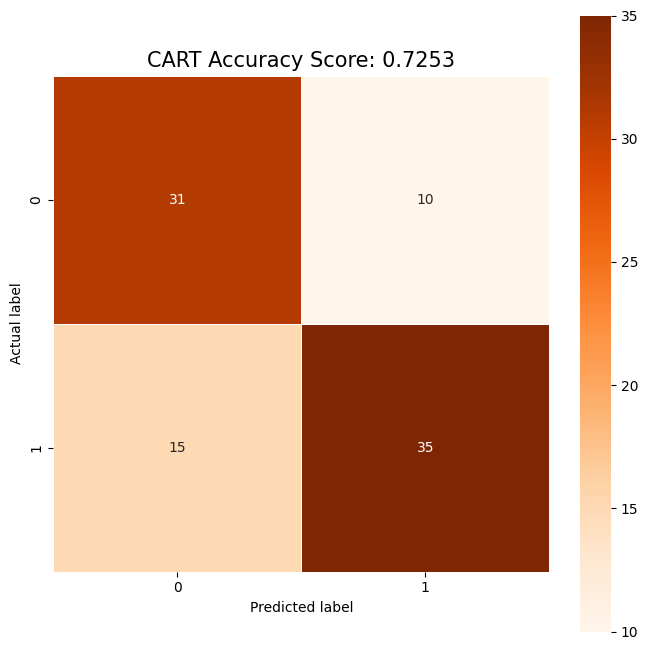

Ma trận nhầm lẫn (hàng = thực tế, cột = dự đoán):
[[31 10]
 [15 35]]


In [14]:
in_ten()
cart_cm = danh_gia_mo_hinh("CART", y_test, cart_pred, LOP, pos_label=1, cmap="Oranges")
print("Ma trận nhầm lẫn (hàng = thực tế, cột = dự đoán):")
print(cart_cm)

Lê Quốc Trung - 6451071082


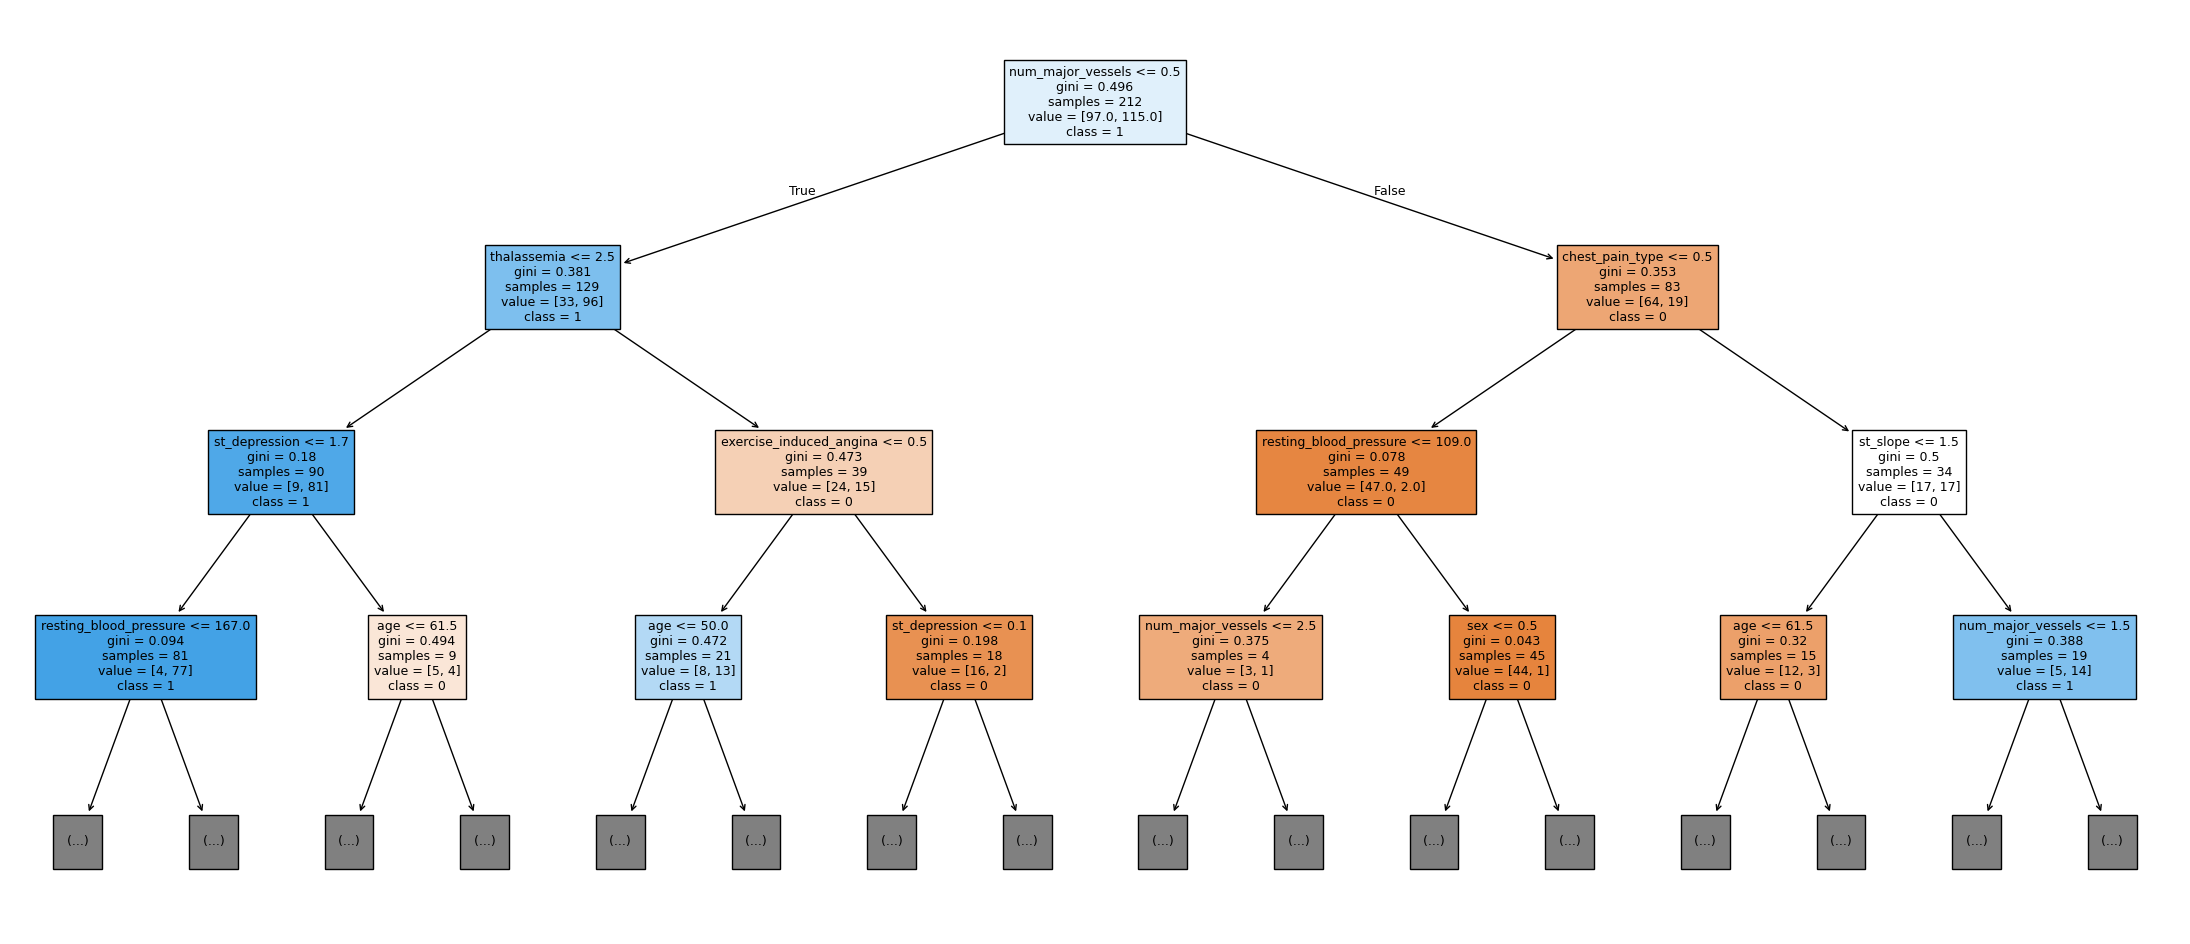

Đã lưu cây vào file: cay_CART_rut_gon.png


In [15]:
in_ten()
ve_cay(clf_cart, X_train.columns, "cay_CART_rut_gon.png", max_depth=3, figsize=(28, 12), fontsize=9)

Lê Quốc Trung - 6451071082


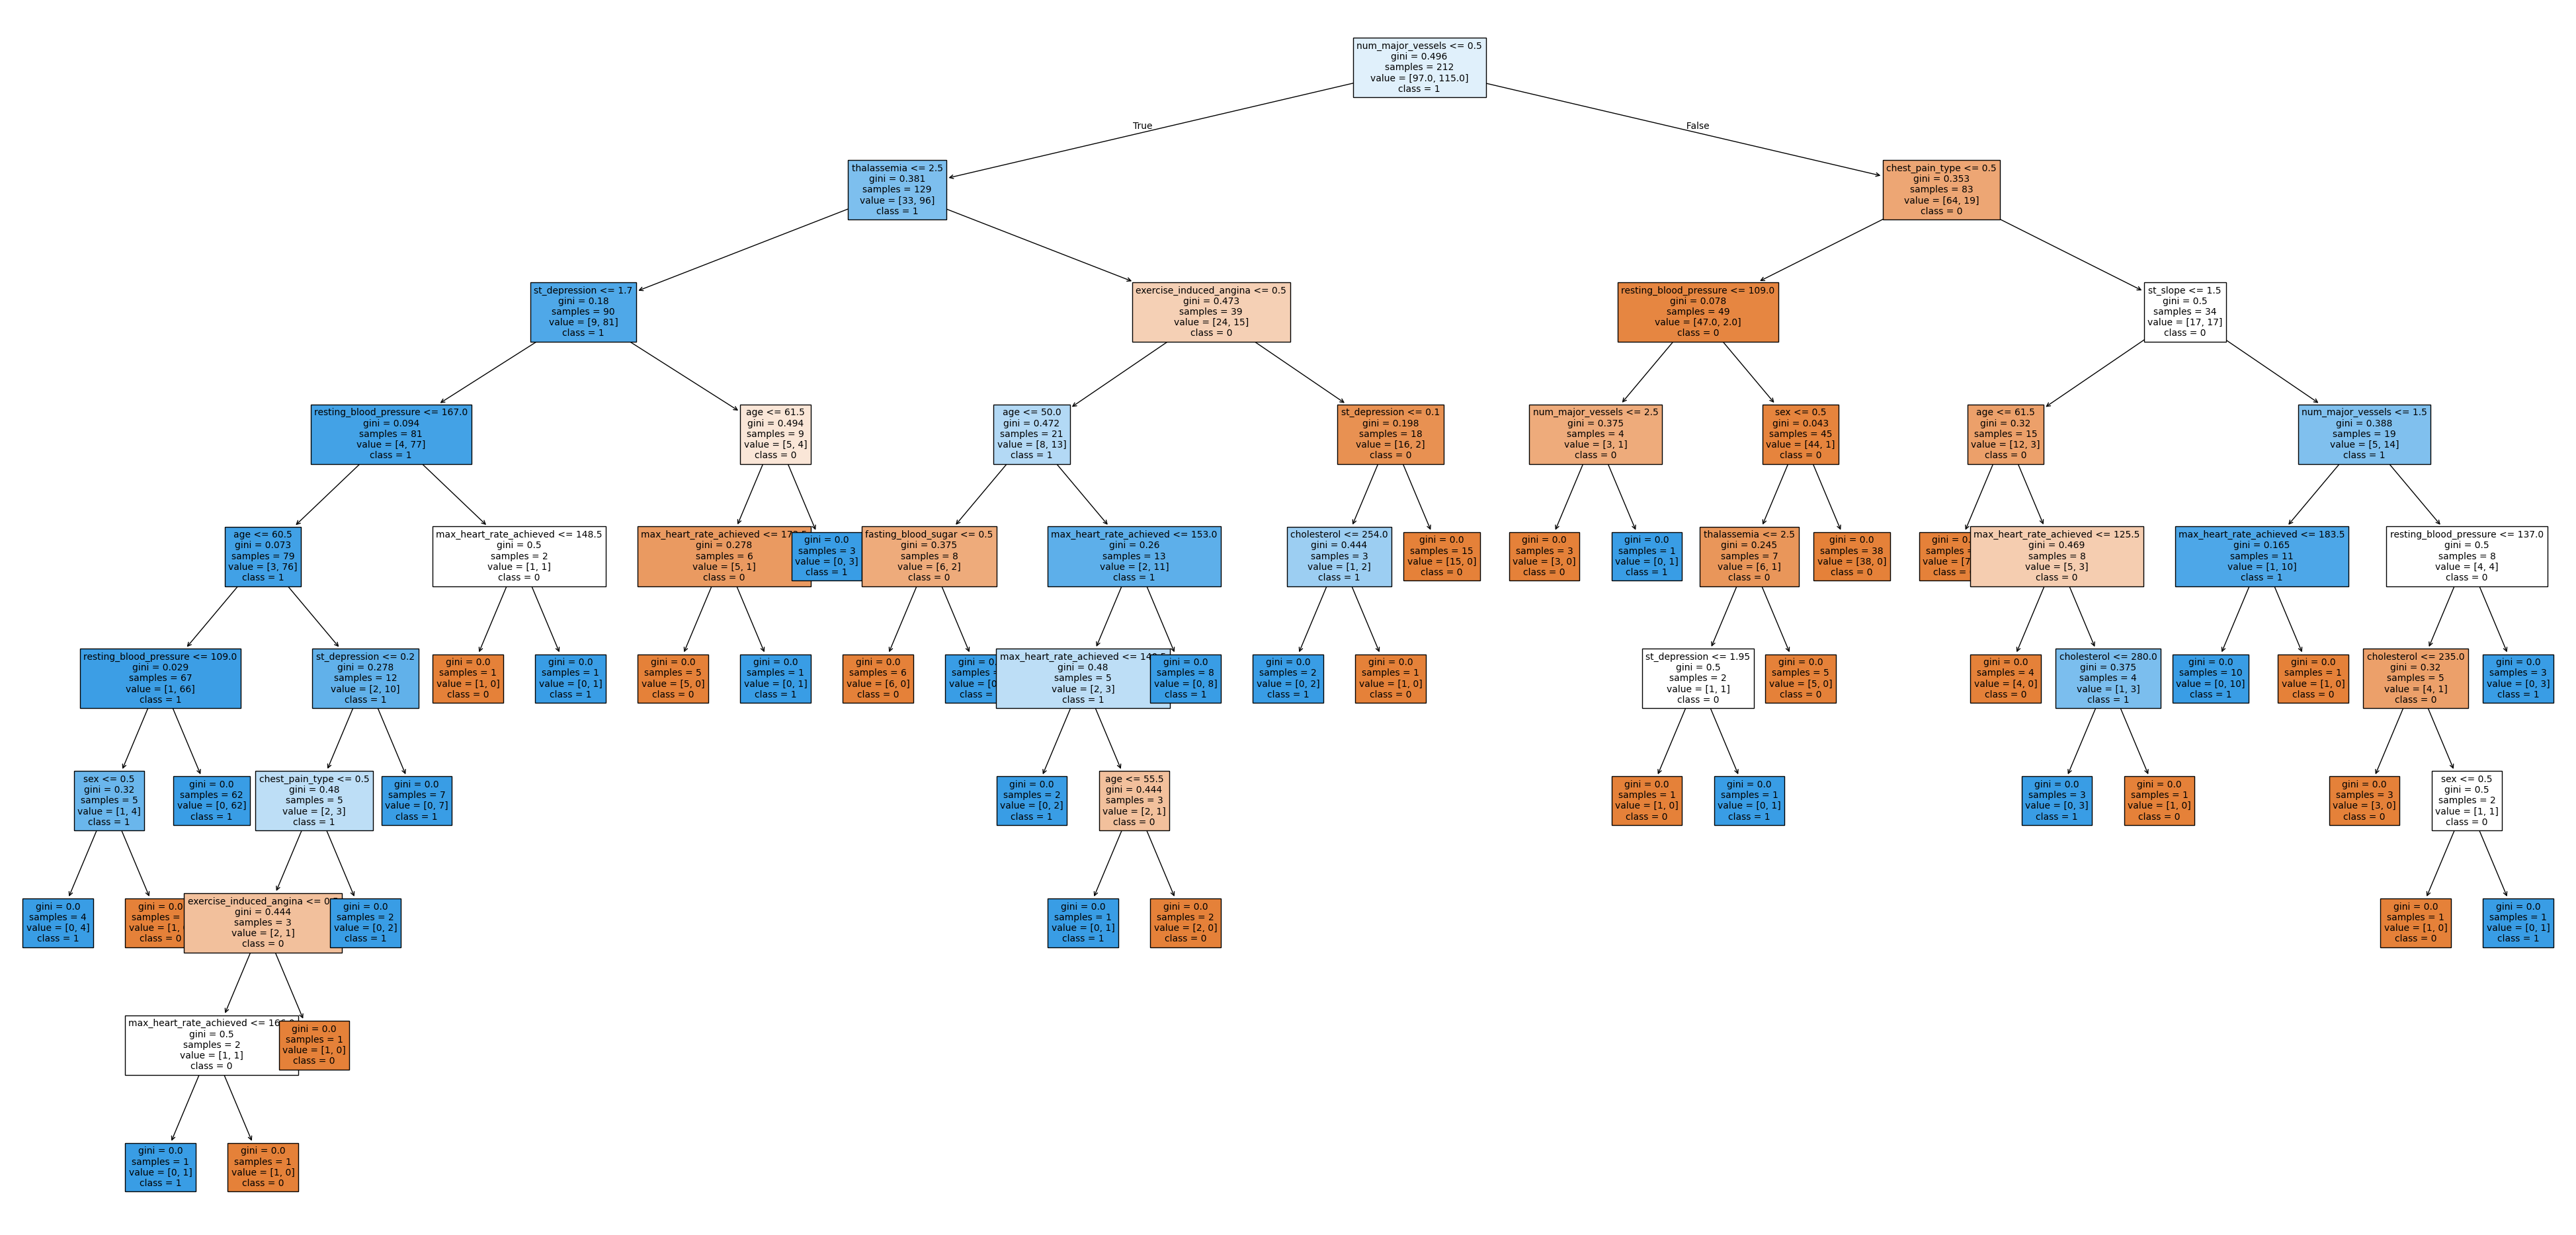

Đã lưu cây vào file: cay_CART.png


In [16]:
in_ten()
VE_CAY_DAY_DU = True
if VE_CAY_DAY_DU:
    ve_cay(clf_cart, X_train.columns, "cay_CART.png", figsize=(50, 24), fontsize=10)

## Câu 9: Xây dựng mô hình phân lớp Naïve Bayes (`GaussianNB`)

In [17]:
in_ten()
gnb = GaussianNB()
bayes_pred = gnb.fit(X_train, y_train).predict(X_test)

Lê Quốc Trung - 6451071082


Lê Quốc Trung - 6451071082
Accuracy: 0.8351648351648352
Report:
               precision    recall  f1-score   support

           0       0.78      0.88      0.83        41
           1       0.89      0.80      0.84        50

    accuracy                           0.84        91
   macro avg       0.84      0.84      0.83        91
weighted avg       0.84      0.84      0.84        91



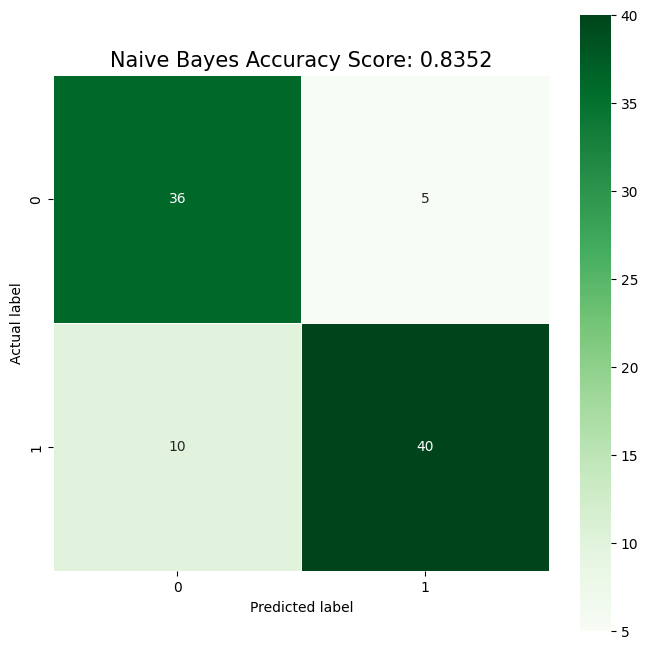

Ma trận nhầm lẫn (hàng = thực tế, cột = dự đoán):
[[36  5]
 [10 40]]


In [18]:
in_ten()
bayes_cm = danh_gia_mo_hinh("Naive Bayes", y_test, bayes_pred, LOP, pos_label=1, cmap="Greens")
print("Ma trận nhầm lẫn (hàng = thực tế, cột = dự đoán):")
print(bayes_cm)

## Câu 10: So sánh kết quả của các mô hình

Lê Quốc Trung - 6451071082


,Accuracy,Precision (macro),Recall (macro),F1 (macro),Precision (weighted),Recall (weighted),F1 (weighted),Precision [1],Recall [1],F1 [1]
ID3,0.7253,0.7258,0.728,0.7247,0.731,0.7253,0.7259,0.7778,0.7,0.7368
CART,0.7253,0.7258,0.728,0.7247,0.731,0.7253,0.7259,0.7778,0.7,0.7368
Naive Bayes,0.8352,0.8357,0.839,0.8348,0.841,0.8352,0.8356,0.8889,0.8,0.8421


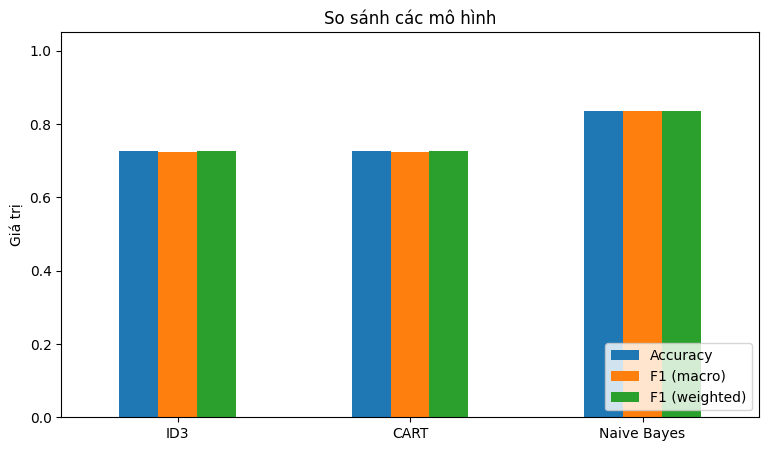

Mô hình có Accuracy cao nhất  : Naive Bayes (0.8352)
Mô hình có F1 (macro) cao nhất: Naive Bayes (0.8348)


In [19]:
in_ten()
bang_ss = pd.DataFrame(ket_qua).T.round(4)
display(bang_ss)

bang_ss[["Accuracy", "F1 (macro)", "F1 (weighted)"]].plot(kind="bar", figsize=(9, 5), rot=0)
plt.title("So sánh các mô hình")
plt.ylabel("Giá trị")
plt.ylim(0, 1.05)
plt.legend(loc="lower right")
plt.show()

print("Mô hình có Accuracy cao nhất  :", bang_ss["Accuracy"].idxmax(), f"({bang_ss['Accuracy'].max():.4f})")
print("Mô hình có F1 (macro) cao nhất:", bang_ss["F1 (macro)"].idxmax(), f"({bang_ss['F1 (macro)'].max():.4f})")

### Nhận xét (đối chiếu với bảng số liệu ở trên rồi chỉnh lại cho khớp kết quả chạy thực tế)
- Tập dữ liệu **rất nhỏ** (~300 dòng, tập kiểm thử chỉ khoảng 90 dòng) nên mỗi mẫu sai làm Accuracy thay đổi ~1% → kết quả dao động mạnh theo `random_state`; cần thận trọng khi kết luận mô hình nào "tốt hơn".
- Cây quyết định không giới hạn độ sâu dễ overfit trên tập nhỏ; `GaussianNB` đơn giản, ít tham số nên đôi khi ổn định hơn.
- Với bài toán y tế, **recall của lớp 1 (có bệnh)** quan trọng hơn precision: bỏ sót bệnh nhân (FN) nguy hiểm hơn báo nhầm (FP).
- Mọi cột đều đã ở dạng số nên không cần one-hot (các cột như `chest_pain_type`, `thalassemia` thực chất là biến phân loại mã hóa số – có thể thử one-hot nếu muốn cải thiện).